In [15]:
import os
import numpy as np
import pandas as pd


# CONFIGURACION

SEED = 42
np.random.seed(SEED)

ALPHA = 0.10
GAMMA = 0.90
EPSILON = 0.20

EPISODIOS = 500
PASOS_POR_EPISODIO = 20

NUM_ESTADOS = 27
NUM_ACCIONES = 4

ACCIONES = {
    0: "Reducir intensidad",
    1: "Mantener intensidad",
    2: "Aumentar intensidad",
    3: "Aumentar recuperacion"
}


# UTILIDADES

def normalizar(serie):
    serie = pd.to_numeric(serie, errors="coerce")

    minimo = serie.min()
    maximo = serie.max()

    if pd.isna(minimo) or pd.isna(maximo) or maximo == minimo:
        return pd.Series(
            np.zeros(len(serie)),
            index=serie.index
        )

    return (serie - minimo) / (maximo - minimo)


def discretizar_3(serie):
    serie = pd.to_numeric(serie, errors="coerce")

    resultado = pd.Series(
        np.nan,
        index=serie.index,
        dtype=float
    )

    validos = serie.notna()

    if validos.sum() == 0:
        return resultado

    rangos = serie[validos].rank(
        method="first"
    )

    try:
        grupos = pd.qcut(
            rangos,
            q=3,
            labels=[0, 1, 2]
        )

        resultado.loc[validos] = grupos.astype(float)

    except ValueError:
        valores = rangos.to_numpy()

        resultado.loc[validos] = np.select(
            [
                valores <= np.quantile(
                    valores,
                    1 / 3
                ),
                valores <= np.quantile(
                    valores,
                    2 / 3
                )
            ],
            [0, 1],
            default=2
        )

    return resultado


def construir_estado(
    fatiga,
    rendimiento,
    carga
):
    fatiga = int(fatiga)
    rendimiento = int(rendimiento)
    carga = int(carga)

    return (
        fatiga * 9
        + rendimiento * 3
        + carga
    )


# BEISBOL

def cargar_beisbol(ruta):

    datos = pd.read_csv(ruta)

    columnas_necesarias = [
        "Fatigue_Score",
        "Performance_Score",
        "Load_Balance_Score",
        "ACL_Risk_Score",
        "Injury_Indicator"
    ]

    faltantes = [
        columna
        for columna in columnas_necesarias
        if columna not in datos.columns
    ]

    if faltantes:
        raise ValueError(
            f"Faltan columnas en el dataset de beisbol: {faltantes}"
        )

    datos = datos.copy()

    datos["fatiga"] = discretizar_3(
        datos["Fatigue_Score"]
    )

    datos["rendimiento"] = discretizar_3(
        datos["Performance_Score"]
    )

    datos["carga"] = discretizar_3(
        datos["Load_Balance_Score"]
    )

    datos["riesgo_lesion"] = normalizar(
        datos["ACL_Risk_Score"]
    )

    datos["lesion"] = pd.to_numeric(
        datos["Injury_Indicator"],
        errors="coerce"
    ).fillna(0)

    datos["rendimiento_norm"] = normalizar(
        datos["Performance_Score"]
    )

    datos["fatiga_norm"] = normalizar(
        datos["Fatigue_Score"]
    )

    datos["recompensa_base"] = (
        2.0 * datos["rendimiento_norm"]
        - 1.5 * datos["fatiga_norm"]
        - 1.5 * datos["riesgo_lesion"]
        - 4.0 * datos["lesion"]
    )

    datos = datos.dropna(
        subset=[
            "fatiga",
            "rendimiento",
            "carga"
        ]
    ).reset_index(drop=True)

    datos["estado"] = datos.apply(
        lambda fila: construir_estado(
            fila["fatiga"],
            fila["rendimiento"],
            fila["carga"]
        ),
        axis=1
    )

    datos["recompensa_base"] = (
        pd.to_numeric(
            datos["recompensa_base"],
            errors="coerce"
        )
        .fillna(0)
    )

    return datos


# FUTBOL

def transformar_formato_futbol(
    datos,
    nombre_columna
):

    datos = datos.copy()

    largo = datos.melt(
        id_vars=[datos.columns[0]],
        value_vars=datos.columns[1:],
        var_name="player_name",
        value_name=nombre_columna
    )

    largo = largo.rename(
        columns={
            datos.columns[0]: "fecha"
        }
    )

    largo["fecha"] = pd.to_datetime(
        largo["fecha"],
        dayfirst=True,
        errors="coerce"
    )

    largo[nombre_columna] = pd.to_numeric(
        largo[nombre_columna],
        errors="coerce"
    )

    return largo


def preparar_game_performance(game):

    game = game.copy()

    game["fecha"] = pd.to_datetime(
        game["timestamp"],
        errors="coerce",
        dayfirst=True
    ).dt.normalize()

    columnas = [
        "team_performance",
        "offensive_performance",
        "defensive_performance"
    ]

    for columna in columnas:

        game[columna] = pd.to_numeric(
            game[columna],
            errors="coerce"
        )

    game["rendimiento_partido"] = (
        game[columnas].mean(axis=1)
    )

    game = game[
        [
            "player_name",
            "fecha",
            "rendimiento_partido"
        ]
    ]

    game = game.dropna(
        subset=[
            "player_name",
            "fecha"
        ]
    )

    game = game.groupby(
        [
            "player_name",
            "fecha"
        ],
        as_index=False
    )["rendimiento_partido"].mean()

    return game


def preparar_injury(injury):

    injury = injury.copy()

    injury["fecha"] = pd.to_datetime(
        injury["timestamp"],
        errors="coerce",
        dayfirst=True
    ).dt.normalize()

    injury["lesion"] = 1

    injury = injury[
        [
            "player_name",
            "fecha",
            "lesion"
        ]
    ]

    injury = injury.dropna(
        subset=[
            "player_name",
            "fecha"
        ]
    )

    injury = injury.drop_duplicates(
        subset=[
            "player_name",
            "fecha"
        ]
    )

    return injury


def cargar_futbol(carpeta):

    ruta_fatiga = os.path.join(
        carpeta,
        "wellness",
        "fatigue.csv"
    )

    ruta_readiness = os.path.join(
        carpeta,
        "wellness",
        "readiness.csv"
    )

    ruta_daily_load = os.path.join(
        carpeta,
        "training-load",
        "daily_load.csv"
    )

    ruta_game = os.path.join(
        carpeta,
        "game-performance",
        "game-performance.csv"
    )

    ruta_injury = os.path.join(
        carpeta,
        "injury",
        "injury.csv"
    )

    fatigue = pd.read_csv(
        ruta_fatiga
    )

    readiness = pd.read_csv(
        ruta_readiness
    )

    daily_load = pd.read_csv(
        ruta_daily_load
    )

    game = pd.read_csv(
        ruta_game
    )

    injury = pd.read_csv(
        ruta_injury
    )

    fatigue = transformar_formato_futbol(
        fatigue,
        "fatiga_original"
    )

    readiness = transformar_formato_futbol(
        readiness,
        "readiness_original"
    )

    daily_load = transformar_formato_futbol(
        daily_load,
        "carga_original"
    )

    datos = fatigue.merge(
        readiness,
        on=[
            "fecha",
            "player_name"
        ],
        how="outer"
    )

    datos = datos.merge(
        daily_load,
        on=[
            "fecha",
            "player_name"
        ],
        how="outer"
    )

    game = preparar_game_performance(
        game
    )

    injury = preparar_injury(
        injury
    )

    datos = datos.merge(
        game,
        on=[
            "fecha",
            "player_name"
        ],
        how="left"
    )

    datos = datos.merge(
        injury,
        on=[
            "fecha",
            "player_name"
        ],
        how="left"
    )

    datos["lesion"] = datos[
        "lesion"
    ].fillna(0)

    datos["fatiga_original"] = pd.to_numeric(
        datos["fatiga_original"],
        errors="coerce"
    )

    datos["readiness_original"] = pd.to_numeric(
        datos["readiness_original"],
        errors="coerce"
    )

    datos["carga_original"] = pd.to_numeric(
        datos["carga_original"],
        errors="coerce"
    )

    datos["fatiga"] = discretizar_3(
        datos["fatiga_original"]
    )

    datos["rendimiento"] = discretizar_3(
        datos["readiness_original"]
    )

    datos["carga"] = discretizar_3(
        datos["carga_original"]
    )

    datos["fatiga_norm"] = normalizar(
        datos["fatiga_original"]
    )

    datos["readiness_norm"] = normalizar(
        datos["readiness_original"]
    )

    datos["carga_norm"] = normalizar(
        datos["carga_original"]
    )

    datos["rendimiento_partido"] = pd.to_numeric(
        datos["rendimiento_partido"],
        errors="coerce"
    )

    datos["rendimiento_partido_norm"] = normalizar(
        datos["rendimiento_partido"]
    )

    datos["rendimiento_partido_norm"] = (
        datos["rendimiento_partido_norm"]
        .fillna(0)
    )

    datos["readiness_norm"] = (
        datos["readiness_norm"]
        .fillna(0)
    )

    datos["fatiga_norm"] = (
        datos["fatiga_norm"]
        .fillna(0)
    )

    datos["carga_norm"] = (
        datos["carga_norm"]
        .fillna(0)
    )

    datos["lesion"] = (
        datos["lesion"]
        .fillna(0)
    )

    datos["recompensa_base"] = (
        2.0
        * datos["rendimiento_partido_norm"]
        + 1.0
        * datos["readiness_norm"]
        - 1.5
        * datos["fatiga_norm"]
        - 1.0
        * datos["carga_norm"]
        - 4.0
        * datos["lesion"]
    )

    datos["recompensa_base"] = (
        pd.to_numeric(
            datos["recompensa_base"],
            errors="coerce"
        )
        .fillna(0)
    )

    datos = datos.dropna(
        subset=[
            "fatiga",
            "rendimiento",
            "carga"
        ]
    ).reset_index(drop=True)

    datos["estado"] = datos.apply(
        lambda fila: construir_estado(
            fila["fatiga"],
            fila["rendimiento"],
            fila["carga"]
        ),
        axis=1
    )

    return datos


# TRANSICIONES

def crear_transiciones(datos):

    estados = datos[
        "estado"
    ].to_numpy()

    recompensas = datos[
        "recompensa_base"
    ].to_numpy()

    if len(estados) < 2:
        raise ValueError(
            "No hay suficientes registros para crear transiciones."
        )

    return estados, recompensas


# RECOMPENSA

def recompensa_accion(
    recompensa_base,
    accion
):

    recompensa = recompensa_base

    if accion == 0:

        recompensa += 0.20

    elif accion == 1:

        recompensa += 0.10

    elif accion == 2:

        recompensa -= 0.20

    elif accion == 3:

        recompensa += 0.30

    return recompensa


# ENTRENAMIENTO

def entrenar_q_learning(
    datos,
    nombre_deporte
):

    estados, recompensas_base = (
        crear_transiciones(datos)
    )

    q_table = np.zeros(
        (
            NUM_ESTADOS,
            NUM_ACCIONES
        )
    )

    recompensas_episodios = []

    for episodio in range(
        EPISODIOS
    ):

        posicion = np.random.randint(
            0,
            len(estados) - 1
        )

        estado = int(
            estados[posicion]
        )

        recompensa_total = 0.0

        for paso in range(
            PASOS_POR_EPISODIO
        ):

            if np.random.rand() < EPSILON:

                accion = np.random.randint(
                    NUM_ACCIONES
                )

            else:

                accion = int(
                    np.argmax(
                        q_table[estado]
                    )
                )

            recompensa = recompensa_accion(
                recompensas_base[posicion],
                accion
            )

            siguiente_posicion = (
                posicion + 1
            ) % len(estados)

            siguiente_estado = int(
                estados[
                    siguiente_posicion
                ]
            )

            q_table[
                estado,
                accion
            ] = (
                q_table[
                    estado,
                    accion
                ]
                + ALPHA
                * (
                    recompensa
                    + GAMMA
                    * np.max(
                        q_table[
                            siguiente_estado
                        ]
                    )
                    - q_table[
                        estado,
                        accion
                    ]
                )
            )

            recompensa_total += recompensa

            estado = siguiente_estado
            posicion = siguiente_posicion

        recompensas_episodios.append(
            recompensa_total
        )

    print(
        f"\nEntrenamiento terminado: "
        f"{nombre_deporte}"
    )

    return (
        q_table,
        recompensas_episodios
    )


# RESULTADOS

def resumen(
    nombre,
    recompensas
):

    print(
        "\n" + "=" * 50
    )

    print(nombre)

    print(
        "=" * 50
    )

    print(
        "Episodios:",
        len(recompensas)
    )

    print(
        "Recompensa media:",
        round(
            np.mean(recompensas),
            4
        )
    )

    print(
        "Recompensa últimos 50:",
        round(
            np.mean(
                recompensas[-50:]
            ),
            4
        )
    )

    print(
        "Recompensa máxima:",
        round(
            np.max(recompensas),
            4
        )
    )


# EJECUCION

if __name__ == "__main__":

    ARCHIVO_BEISBOL = (
        "/content/beisbol_dataset/"
        "collegiate_athlete_injury_dataset.csv"
    )

    CARPETA_FUTBOL = (
        "/content/soccer_subjective/"
        "subjective"
    )

    print(
        "Cargando dataset de Béisbol..."
    )

    beisbol = cargar_beisbol(
        ARCHIVO_BEISBOL
    )

    print(
        "Registros validos de beisbol:",
        len(beisbol)
    )

    print(
        "\nCargando dataset de Fútbol..."
    )

    futbol = cargar_futbol(
        CARPETA_FUTBOL
    )

    print(
        "Registros validos de futbol:",
        len(futbol)
    )

    resultados = {}
    tablas_q = {}

    for deporte, datos in [
        ("Beisbol", beisbol),
        ("Futbol", futbol)
    ]:

        q, recompensas = (
            entrenar_q_learning(
                datos,
                deporte
            )
        )

        tablas_q[deporte] = q
        resultados[deporte] = recompensas

        resumen(
            deporte,
            recompensas
        )

    filas = []

    for deporte, recompensas in (
        resultados.items()
    ):

        filas.append({
            "deporte": deporte,
            "algoritmo": "Q-Learning",
            "recompensa_media": np.mean(
                recompensas
            ),
            "recompensa_ultimos_50": np.mean(
                recompensas[-50:]
            ),
            "recompensa_maxima": np.max(
                recompensas
            )
        })

    resultados_df = pd.DataFrame(
        filas
    )

    resultados_df.to_csv(
        "/content/resultados_IA_deportes.csv",
        index=False
    )

    print(
        "\nResultados guardados en "
        "/content/resultados_IA_deportes.csv"
    )

    print(
        "\nResumen final:"
    )

    print(
        resultados_df
    )

Cargando dataset de Béisbol...
Registros validos de beisbol: 200

Cargando dataset de Fútbol...
Registros validos de futbol: 16983

Entrenamiento terminado: Beisbol

Beisbol
Episodios: 500
Recompensa media: -11.278
Recompensa últimos 50: -9.4827
Recompensa máxima: 8.0515

Entrenamiento terminado: Futbol

Futbol
Episodios: 500
Recompensa media: -0.4094
Recompensa últimos 50: -0.4288
Recompensa máxima: 17.4253

Resultados guardados en /content/resultados_IA_deportes.csv

Resumen final:
   deporte   algoritmo  recompensa_media  recompensa_ultimos_50  \
0  Beisbol  Q-Learning        -11.278001              -9.482709   
1   Futbol  Q-Learning         -0.409380              -0.428825   

   recompensa_maxima  
0           8.051531  
1          17.425292  


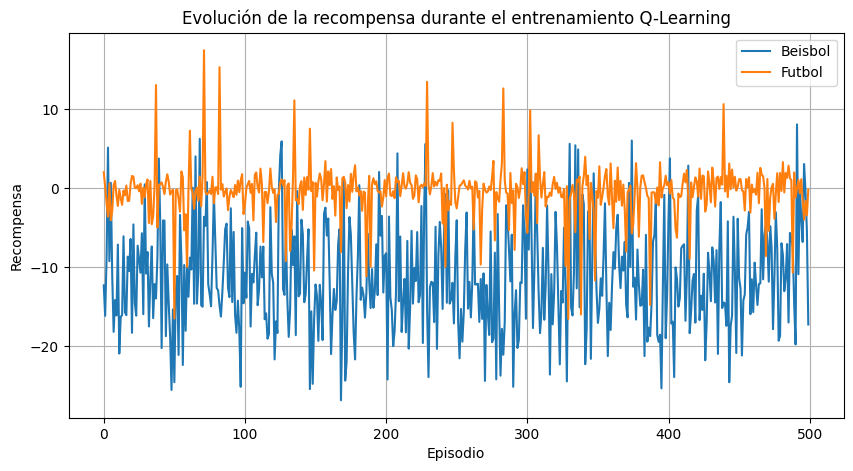

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

for deporte, recompensas in resultados.items():
    plt.plot(recompensas, label=deporte)

plt.xlabel("Episodio")
plt.ylabel("Recompensa")
plt.title("Evolución de la recompensa durante el entrenamiento Q-Learning")
plt.legend()
plt.grid(True)
plt.show()